In [1]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader
from torchvision.io import read_image
from torchvision.transforms import Resize

from sklearn.model_selection import train_test_split

In [2]:
SEED = 59

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

Device: cpu


In [5]:
train_dir = "data//train"
test_dir = "data//test"

img_height = 128
img_width = 128


In [6]:
print("Train exists:", os.path.exists(train_dir))
print("Test exists:", os.path.exists(test_dir))

Train exists: True
Test exists: True


In [7]:
classes = sorted(os.listdir(train_dir)) 
print(classes)

['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']


In [8]:
label2idx = {
    label: idx
    for idx, label in enumerate(classes)
}

idx2label = {
    idx: label
    for label, idx in label2idx.items()
}

print("label2idx:")
print(label2idx)

print()

print("idx2label:")
print(idx2label)

label2idx:
{'angry': 0, 'disgust': 1, 'fear': 2, 'happy': 3, 'neutral': 4, 'sad': 5, 'surprise': 6}

idx2label:
{0: 'angry', 1: 'disgust', 2: 'fear', 3: 'happy', 4: 'neutral', 5: 'sad', 6: 'surprise'}


In [9]:
class ImageDataset(Dataset):
    def __init__(
        self,
        root_dir,
        label2idx,
        mode="train",
        val_size=0.2,
        norm=True,
        random_state=59
    ):
        self.root_dir = root_dir
        self.label2idx = label2idx
        self.mode = mode
        self.norm = norm

        self.img_files = []
        self.img_labels = []

        self.read_img_files()

        if mode in ["train", "val"]:
            train_files, val_files, train_labels, val_labels = train_test_split(
                self.img_files,
                self.img_labels,
                test_size=val_size,
                random_state=random_state,
                stratify=self.img_labels
            )

            if mode == "train":
                self.img_files = train_files
                self.img_labels = train_labels

            elif mode == "val":
                self.img_files = val_files
                self.img_labels = val_labels

        self.resize = Resize(
            (img_height, img_width)
        )

    def read_img_files(self):
        for label in sorted(os.listdir(self.root_dir)):

            class_dir = os.path.join(
                self.root_dir,
                label
            )

            if not os.path.isdir(class_dir):
                continue

            for filename in os.listdir(class_dir):

                img_path = os.path.join(
                    class_dir,
                    filename
                )

                self.img_files.append(img_path)

                self.img_labels.append(
                    self.label2idx[label]
                )

    def __len__(self):
        return len(self.img_files)

    def __getitem__(self, idx):

        img_path = self.img_files[idx]
        label = self.img_labels[idx]

        img = read_image(img_path)

        img = self.resize(img)

        img = img.float()

        if self.norm:
            img = (img / 127.5) - 1

        label = torch.tensor(
            label,
            dtype=torch.long
        )

        return img, label

In [10]:
train_dataset = ImageDataset(
    root_dir=train_dir,
    label2idx=label2idx,
    mode="train",
    val_size=0.2,
    norm=True,
    random_state=SEED
)

val_dataset = ImageDataset(
    root_dir=train_dir,
    label2idx=label2idx,
    mode="val",
    val_size=0.2,
    norm=True,
    random_state=SEED
)

test_dataset = ImageDataset(
    root_dir=test_dir,
    label2idx=label2idx,
    mode="test",
    norm=True,
    random_state=SEED
)

In [11]:
print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

Train: 22967
Validation: 5742
Test: 7178


In [12]:
batch_size = 256

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

In [13]:
images, labels = next(iter(train_loader))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)

print("Images dtype:", images.dtype)
print("Labels dtype:", labels.dtype)

print("Min pixel:", images.min())
print("Max pixel:", images.max())

Images shape: torch.Size([256, 1, 128, 128])
Labels shape: torch.Size([256])
Images dtype: torch.float32
Labels dtype: torch.int64
Min pixel: tensor(-1.)
Max pixel: tensor(1.)


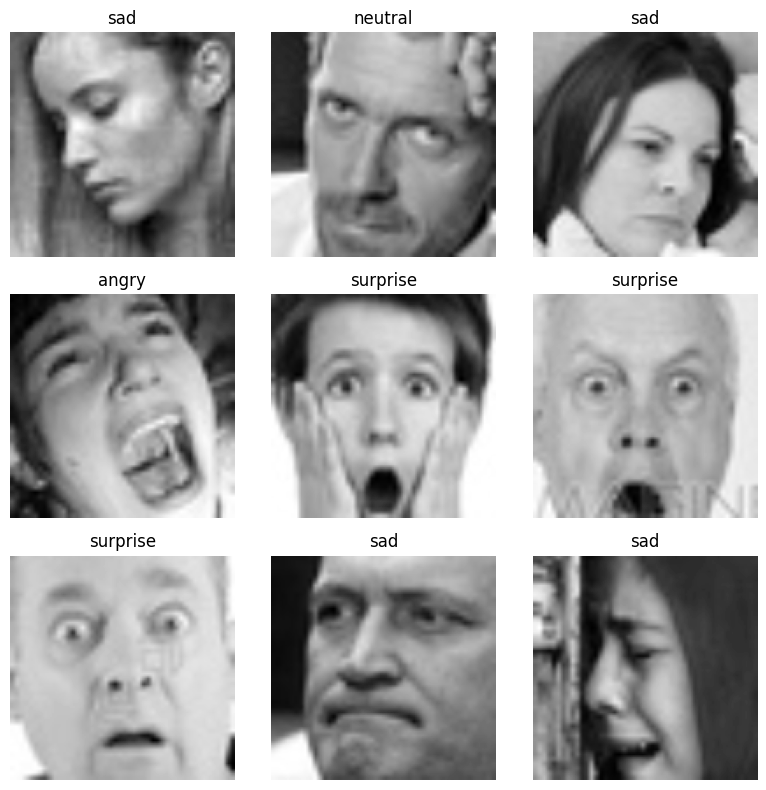

In [14]:
images, labels = next(iter(train_loader))

fig, axes = plt.subplots(
    3,
    3,
    figsize=(8, 8)
)

for i, ax in enumerate(axes.flat):

    img = images[i].squeeze()

    img = (img + 1) / 2

    ax.imshow(
        img,
        cmap="gray"
    )

    label_idx = labels[i].item()

    ax.set_title(
        idx2label[label_idx]
    )

    ax.axis("off")

plt.tight_layout()
plt.show()

In [15]:
class MLP(nn.Module):
    def __init__(
        self,
        input_dims,
        hidden_dims,
        output_dims
    ):
        super().__init__()

        self.flatten = nn.Flatten()

        self.fc1 = nn.Linear(
            input_dims,
            hidden_dims * 4
        )

        self.fc2 = nn.Linear(
            hidden_dims * 4,
            hidden_dims * 2
        )

        self.fc3 = nn.Linear(
            hidden_dims * 2,
            hidden_dims
        )

        self.fc4 = nn.Linear(
            hidden_dims,
            output_dims
        )

    def forward(self, x):

        x = self.flatten(x)

        x = F.relu(
            self.fc1(x)
        )

        x = F.relu(
            self.fc2(x)
        )

        x = F.relu(
            self.fc3(x)
        )

        x = self.fc4(x)

        return x

In [16]:
input_dims = img_height * img_width
hidden_dims = 64
output_dims = len(classes)

model = MLP(
    input_dims=input_dims,
    hidden_dims=hidden_dims,
    output_dims=output_dims
).to(device)

print(model)

MLP(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=16384, out_features=256, bias=True)
  (fc2): Linear(in_features=256, out_features=128, bias=True)
  (fc3): Linear(in_features=128, out_features=64, bias=True)
  (fc4): Linear(in_features=64, out_features=7, bias=True)
)


In [17]:
images, labels = next(iter(train_loader))

images = images.to(device)
labels = labels.to(device)

outputs = model(images)

print("Images:", images.shape)
print("Outputs:", outputs.shape)
print("Labels:", labels.shape)

Images: torch.Size([256, 1, 128, 128])
Outputs: torch.Size([256, 7])
Labels: torch.Size([256])


In [18]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.SGD(
    model.parameters(),
    lr=0.01
)

epochs = 40

In [19]:
def compute_accuracy(y_pred, y_true):

    _, predicted_classes = torch.max(
        y_pred,
        dim=1
    )

    correct = (
        predicted_classes == y_true
    ).sum().item()

    accuracy = correct / y_true.size(0)

    return accuracy

In [20]:
train_losses = []
val_losses = []

train_accuracies = []
val_accuracies = []

In [21]:
for epoch in range(epochs):

    # =========================
    # TRAIN
    # =========================

    model.train()

    total_train_loss = 0

    train_preds = []
    train_targets = []

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(
            outputs,
            labels
        )

        loss.backward()

        optimizer.step()

        total_train_loss += (
            loss.item() * images.size(0)
        )

        train_preds.append(
            outputs.detach().cpu()
        )

        train_targets.append(
            labels.detach().cpu()
        )


    train_loss = (
        total_train_loss
        / len(train_loader.dataset)
    )

    train_preds = torch.cat(train_preds)
    train_targets = torch.cat(train_targets)

    train_acc = compute_accuracy(
        train_preds,
        train_targets
    )


    # =========================
    # VALIDATION
    # =========================

    model.eval()

    total_val_loss = 0

    val_preds = []
    val_targets = []

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

            total_val_loss += (
                loss.item() * images.size(0)
            )

            val_preds.append(
                outputs.detach().cpu()
            )

            val_targets.append(
                labels.detach().cpu()
            )


    val_loss = (
        total_val_loss
        / len(val_loader.dataset)
    )

    val_preds = torch.cat(val_preds)
    val_targets = torch.cat(val_targets)

    val_acc = compute_accuracy(
        val_preds,
        val_targets
    )


    # =========================
    # SAVE HISTORY
    # =========================

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)


    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

Epoch 1/40 | Train Loss: 1.9118 | Train Acc: 0.2493 | Val Loss: 1.8880 | Val Acc: 0.2515
Epoch 2/40 | Train Loss: 1.8649 | Train Acc: 0.2522 | Val Loss: 1.8438 | Val Acc: 0.2511
Epoch 3/40 | Train Loss: 1.8254 | Train Acc: 0.2540 | Val Loss: 1.8121 | Val Acc: 0.2581
Epoch 4/40 | Train Loss: 1.7984 | Train Acc: 0.2596 | Val Loss: 1.7908 | Val Acc: 0.2611
Epoch 5/40 | Train Loss: 1.7791 | Train Acc: 0.2680 | Val Loss: 1.7734 | Val Acc: 0.2785
Epoch 6/40 | Train Loss: 1.7618 | Train Acc: 0.2871 | Val Loss: 1.7560 | Val Acc: 0.2879
Epoch 7/40 | Train Loss: 1.7433 | Train Acc: 0.3008 | Val Loss: 1.7353 | Val Acc: 0.3077
Epoch 8/40 | Train Loss: 1.7216 | Train Acc: 0.3175 | Val Loss: 1.7133 | Val Acc: 0.3161
Epoch 9/40 | Train Loss: 1.6988 | Train Acc: 0.3307 | Val Loss: 1.6915 | Val Acc: 0.3354
Epoch 10/40 | Train Loss: 1.6776 | Train Acc: 0.3423 | Val Loss: 1.6736 | Val Acc: 0.3445
Epoch 11/40 | Train Loss: 1.6604 | Train Acc: 0.3536 | Val Loss: 1.6598 | Val Acc: 0.3511
Epoch 12/40 | Train

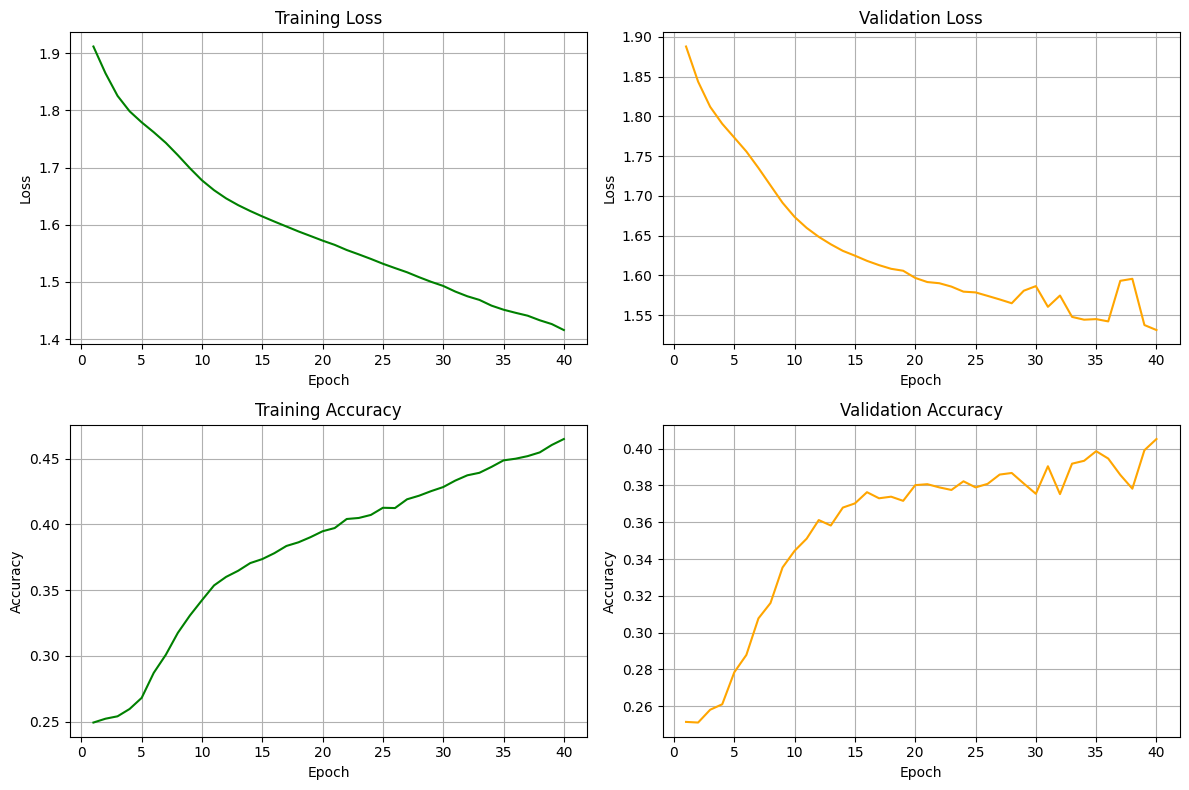

In [22]:
epochs_range = range(
    1,
    len(train_losses) + 1
)

fig, axes = plt.subplots(
    2,
    2,
    figsize=(12, 8)
)

axes[0, 0].plot(
    epochs_range,
    train_losses,
    color="green"
)
axes[0, 0].set_title("Training Loss")
axes[0, 0].set_xlabel("Epoch")
axes[0, 0].set_ylabel("Loss")
axes[0, 0].grid(True)


axes[0, 1].plot(
    epochs_range,
    val_losses,
    color="orange"
)
axes[0, 1].set_title("Validation Loss")
axes[0, 1].set_xlabel("Epoch")
axes[0, 1].set_ylabel("Loss")
axes[0, 1].grid(True)


axes[1, 0].plot(
    epochs_range,
    train_accuracies,
    color="green"
)
axes[1, 0].set_title("Training Accuracy")
axes[1, 0].set_xlabel("Epoch")
axes[1, 0].set_ylabel("Accuracy")
axes[1, 0].grid(True)


axes[1, 1].plot(
    epochs_range,
    val_accuracies,
    color="orange"
)
axes[1, 1].set_title("Validation Accuracy")
axes[1, 1].set_xlabel("Epoch")
axes[1, 1].set_ylabel("Accuracy")
axes[1, 1].grid(True)


plt.tight_layout()
plt.show()

In [23]:
model.eval()

test_preds = []
test_targets = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        test_preds.append(
            outputs.detach().cpu()
        )

        test_targets.append(
            labels.detach().cpu()
        )

In [24]:
test_preds = torch.cat(test_preds)
test_targets = torch.cat(test_targets)

In [25]:
test_accuracy = compute_accuracy(
    test_preds,
    test_targets
)

print(
    f"Test Accuracy: "
    f"{test_accuracy:.4f}"
)

print(
    f"Test Accuracy: "
    f"{test_accuracy * 100:.2f}%"
)

Test Accuracy: 0.4121
Test Accuracy: 41.21%


In [26]:
_, predicted_classes = torch.max(
    test_preds,
    dim=1
)

for i in range(10):

    pred = predicted_classes[i].item()
    true = test_targets[i].item()

    print(
        f"Predicted: {idx2label[pred]:10s} | "
        f"Actual: {idx2label[true]}"
    )

Predicted: happy      | Actual: angry
Predicted: happy      | Actual: angry
Predicted: happy      | Actual: angry
Predicted: sad        | Actual: angry
Predicted: happy      | Actual: angry
Predicted: fear       | Actual: angry
Predicted: fear       | Actual: angry
Predicted: happy      | Actual: angry
Predicted: sad        | Actual: angry
Predicted: angry      | Actual: angry
